In [3]:
# %%
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

from assignment_1.modules.tasks.task2 import (  # adjust path
    TASK2_FEATURES,
    task2_pair_features,
)
from assignment_1.modules.util import load_csv, make_pair_validation

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
DATA_DIR = "../data"
train = load_csv("tasks_1_2_train.csv", DATA_DIR)
test = load_csv("task_2_test.csv", DATA_DIR)

# %%
tr, pairs = make_pair_validation(train, seed=0)          # same validation as run_task2
                       # columns = TASK2_FEATURES, item1 − item2


In [ ]:
X = task2_pair_features(tr, pairs) 
y = (pairs["which"] == pairs["item1"]).astype(int).to_numpy()
half = np.random.default_rng(0).random(len(pairs)) < 0.5
col = {c: k for k, c in enumerate(TASK2_FEATURES)}

rows per user — val: {'mean': 6.850813277397513, 'max': 530.0} | test: {'mean': 1.942690626517727, 'max': 60.0}


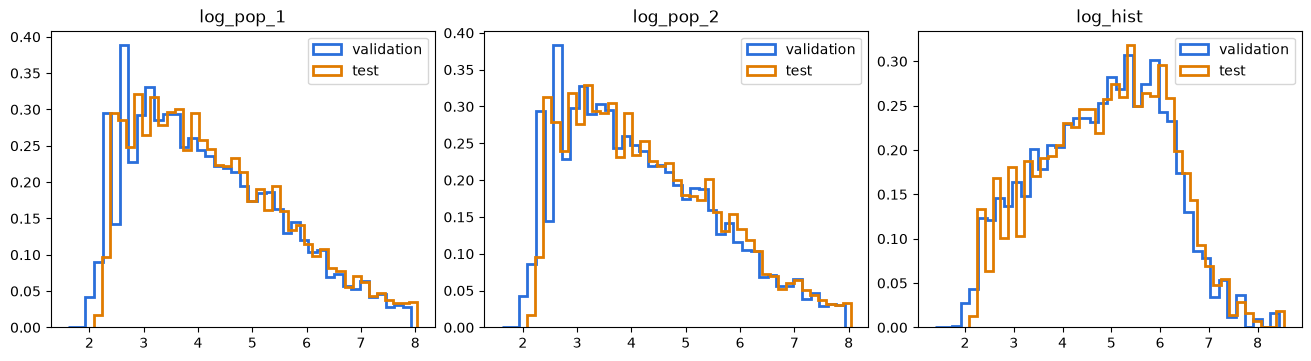

In [ ]:
def cand_stats(df, ref):
    pop = ref["item"].value_counts()
    ulen = ref["user"].value_counts()
    return pd.DataFrame({
        "log_pop_1": np.log1p(df["item1"].map(pop).fillna(0)),
        "log_pop_2": np.log1p(df["item2"].map(pop).fillna(0)),
        "log_hist":  np.log1p(df["user"].map(ulen).fillna(0)),
    })

v, t = cand_stats(pairs, tr), cand_stats(test, train)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), constrained_layout=True)
for ax, c in zip(axes, v.columns):
    ax.hist(v[c], bins=40, density=True, histtype="step", lw=2, color="#2a6fdb", label="validation")
    ax.hist(t[c], bins=40, density=True, histtype="step", lw=2, color="#e07b00", label="test")
    ax.set_title(c); ax.legend()

print("rows per user — val:", pairs.groupby("user").size().describe()[["mean", "max"]].to_dict(),
      "| test:", test.groupby("user").size().describe()[["mean", "max"]].to_dict())

In [ ]:
# %%
ho = ~half
lr = LogisticRegression(max_iter=1000).fit(X[half], y[half])
p = lr.predict_proba(X[ho])[:, 1]
correct = (p >= 0.5).astype(int) == y[ho]
print(f"held-out acc {correct.mean():.4f}  (expect ≈ 0.9371)")      # confirms packaged == notebook

hist_len = pairs["user"].map(tr["user"].value_counts()).fillna(0).to_numpy()[ho]
pop_gap = np.abs(X[ho, col["log_pop"]])
cos_gap = np.abs(X[ho, col["cos_sum"]])
margin = np.abs(p - 0.5)

held-out acc 0.9371  (expect ≈ 0.9371)


In [ ]:
for name, x, bins in [("hist_len", hist_len, [0, 1, 2, 3, 5, 10, 20, 50, 1e5]),
                      ("pop_gap", pop_gap, [0, .1, .25, .5, 1, 2, 10]),
                      ("cos_gap", cos_gap, [0, 1e-6, .01, .05, .1, .5, 1e3]),
                      ("margin", margin, [0, .05, .1, .2, .3, .4, .5])]:
    g = (pd.DataFrame({"b": pd.cut(x, bins, include_lowest=True), "c": correct})
           .groupby("b", observed=True)["c"].agg(["mean", "size"]))
    print(f"\n{name}\n{g.round(4)}")


hist_len
                    mean   size
b                              
(2.0, 3.0]        1.0000      2
(3.0, 5.0]        0.9048     21
(5.0, 10.0]       0.9367   3241
(10.0, 20.0]      0.9340   7945
(20.0, 50.0]      0.9372  14995
(50.0, 100000.0]  0.9374  66577

pop_gap
                 mean   size
b                           
(-0.001, 0.1]  0.9391   4189
(0.1, 0.25]    0.9380   5952
(0.25, 0.5]    0.9301   9761
(0.5, 1.0]     0.9362  17356
(1.0, 2.0]     0.9360  27116
(2.0, 10.0]    0.9405  28407

cos_gap
                   mean   size
b                             
(-0.001, 1e-06]  0.8788     66
(1e-06, 0.01]    0.8435    428
(0.01, 0.05]     0.8497   1730
(0.05, 0.1]      0.8586   2023
(0.1, 0.5]       0.9020  12388
(0.5, 1000.0]    0.9474  76146

margin
                  mean   size
b                            
(-0.001, 0.05]  0.5414   1618
(0.05, 0.1]     0.5751   1638
(0.1, 0.2]      0.6518   3688
(0.2, 0.3]      0.7723   4625
(0.3, 0.4]      0.8661   7698
(0.4, 0.5]      0.

In [ ]:
low = margin < 0.1                        # ≈ 3.3k held-out rows at ~0.56 accuracy
Xh, yh = X[ho], y[ho]
print(f"model on low-confidence rows: {correct[low].mean():.4f}  (n={low.sum():,})")
for c, k in col.items():
    pred = (Xh[low, k] > 0).astype(int)   # positive difference -> item1
    print(f"  {c:<9} alone: {(pred == yh[low]).mean():.4f}   ties {np.mean(Xh[low, k] == 0):.1%}")

model on low-confidence rows: 0.5584  (n=3,256)
  bpr       alone: 0.5046   ties 0.0%
  log_pop   alone: 0.4893   ties 1.1%
  cos_sum   alone: 0.5031   ties 0.3%
  cos_max   alone: 0.5353   ties 0.3%
  cos_mean  alone: 0.5031   ties 0.3%


In [6]:
def seen_check(test, train, name):
    hist = set(train["user"] + "|" + train["item"])
    s1 = (test["user"] + "|" + test["item1"]).isin(hist)
    s2 = (test["user"] + "|" + test["item2"]).isin(hist)
    print(f"{name}: item1 seen {s1.mean():.2%} | item2 seen {s2.mean():.2%} | "
          f"exactly one {(s1 ^ s2).mean():.2%} | both {(s1 & s2).mean():.2%}")

seen_check(load_csv("task_2_test.csv", DATA_DIR), load_csv("tasks_1_2_train.csv", DATA_DIR), "Task 2")
seen_check(load_csv("task_4_test.csv", DATA_DIR), load_csv("tasks_3_4_train.csv", DATA_DIR), "Task 4")
seen_check(load_csv("task_5_test.csv", DATA_DIR), load_csv("task_5_train.csv", DATA_DIR), "Task 5")

Task 2: item1 seen 0.90% | item2 seen 1.02% | exactly one 1.92% | both 0.00%
Task 4: item1 seen 2.51% | item2 seen 2.56% | exactly one 5.07% | both 0.00%
Task 5: item1 seen 0.34% | item2 seen 0.35% | exactly one 0.69% | both 0.00%


In [7]:
def seen_rows_now(test_file, train_file, pred_file):
    test, train = load_csv(test_file, DATA_DIR), load_csv(train_file, DATA_DIR)
    pred = pd.read_csv(pred_file)                      # check the predicted-item column name
    hist = set(train["user"] + "|" + train["item"])
    s1 = (test["user"] + "|" + test["item1"]).isin(hist)
    s2 = (test["user"] + "|" + test["item2"]).isin(hist)
    one = (s1 ^ s2).to_numpy()
    seen_item = np.where(s1, test["item1"], test["item2"])
    picks_seen = (pred["which"].to_numpy() == seen_item)[one].mean()
    print(f"{test_file}: rows {one.mean():.2%} | current preds pick the SEEN item on {picks_seen:.1%} of them")

seen_rows_now("task_2_test.csv", "tasks_1_2_train.csv", "../dist/task_2_predictions.csv")
seen_rows_now("task_4_test.csv", "tasks_3_4_train.csv", "../dist/task_4_predictions.csv")
seen_rows_now("task_5_test.csv", "task_5_train.csv", "../dist/task_5_predictions.csv")

task_2_test.csv: rows 1.92% | current preds pick the SEEN item on 54.0% of them
task_4_test.csv: rows 5.07% | current preds pick the SEEN item on 38.8% of them
task_5_test.csv: rows 0.69% | current preds pick the SEEN item on 61.9% of them
